In [63]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random
import shutil

from pathlib import Path
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
dataset_path = Path(
    "../dataset/raw"
)

print("Dataset Exists:", dataset_path.exists())
print("Total Classes:", len(list(dataset_path.iterdir())))
print("Classes:", [p.name for p in dataset_path.iterdir() if p.is_dir()])

Dataset Exists: True
Total Classes: 10
Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [3]:
random.seed(36)

selected_images = []

image_extensions = [".jpg", ".jpeg", ".png"]

for class_folder in dataset_path.iterdir():

    if class_folder.is_dir():

        images = [
            p for p in class_folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        ]

        sample_count = max(1, int(len(images) * 0.30))

        selected = random.sample(
            images,
            sample_count
        )

        selected_images.extend(selected)

print("Total selected images:", len(selected_images))

Total selected images: 4799


In [4]:
small_dataset_path = Path("/content/tomato_30_percent")

if small_dataset_path.exists():
    shutil.rmtree(small_dataset_path)

small_dataset_path.mkdir(parents=True, exist_ok=True)

for image_path in selected_images:

    class_name = image_path.parent.name

    target_folder = small_dataset_path / class_name
    target_folder.mkdir(parents=True, exist_ok=True)

    shutil.copy2(
        image_path,
        target_folder / image_path.name
    )

print("30% dataset created successfully!")

30% dataset created successfully!


In [5]:
for class_folder in sorted(small_dataset_path.iterdir()):

    if class_folder.is_dir():

        count = len(list(class_folder.iterdir()))

        print(class_folder.name, ":", count)

Tomato__Target_Spot : 421
Tomato__Tomato_mosaic_virus : 111
Tomato__Tomato_YellowLeaf__Curl_Virus : 962
Tomato_Bacterial_spot : 638
Tomato_Early_blight : 300
Tomato_healthy : 477
Tomato_Late_blight : 572
Tomato_Leaf_Mold : 285
Tomato_Septoria_leaf_spot : 531
Tomato_Spider_mites_Two_spotted_spider_mite : 502


In [6]:
from pathlib import Path

small_dataset_path = Path("/content/tomato_30_percent")

print(small_dataset_path.exists())

True


In [7]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    small_dataset_path,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int"
)

temp_dataset = tf.keras.utils.image_dataset_from_directory(
    small_dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int"
)

class_names = train_dataset.class_names
num_classes = len(class_names)

val_batches = tf.data.experimental.cardinality(temp_dataset)

validation_dataset = temp_dataset.take(val_batches // 2)
test_dataset = temp_dataset.skip(val_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.shuffle(500).prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

Found 4799 files belonging to 10 classes.
Using 3360 files for training.
Found 4799 files belonging to 10 classes.
Using 1439 files for validation.


In [8]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [35]:
base_model.trainable = False

In [39]:
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)



Total layers: 154
Trainable: False


In [40]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

inputs = tf.keras.Input(shape=(160, 160, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax",
    dtype="float32"
)(x)

model = tf.keras.Model(inputs, outputs)

In [41]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [48]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [49]:
print("Model compiled successfully!")
print("Number of classes:", num_classes)

Model compiled successfully!
Number of classes: 10


In [45]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

In [50]:

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=8,
    callbacks=[early_stop]
)

Epoch 1/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 40s 336ms/step - accuracy: 0.9051 - loss: 0.2674 - val_accuracy: 0.8608 - val_loss: 0.4132
Epoch 2/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 41s 380ms/step - accuracy: 0.9226 - loss: 0.2281 - val_accuracy: 0.8693 - val_loss: 0.4161
Epoch 3/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 38s 345ms/step - accuracy: 0.9280 - loss: 0.2242 - val_accuracy: 0.8608 - val_loss: 0.3619
Epoch 4/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 38s 349ms/step - accuracy: 0.9241 - loss: 0.2219 - val_accuracy: 0.8622 - val_loss: 0.3953
Epoch 5/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 37s 341ms/step - accuracy: 0.9274 - loss: 0.2080 - val_accuracy: 0.8651 - val_loss: 0.3714
Epoch 6/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 36s 330ms/step - accuracy: 0.9354 - loss: 0.1958 - val_accuracy: 0.8764 - val_loss: 0.3599
Epoch 7/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 35s 322ms/step - accuracy: 0.9345 - loss: 0.1882 - val_accuracy: 0.8679 - val_loss: 0.3635
Epoch 8/8
105/105 ━━━━━━━━━━━━━━━━━━━━ 36s 333ms/step - accuracy: 0.9369 - loss: 0.1759 - 

In [66]:
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "mobilenetv2_training_history.csv",
    index=False
)

print(history_df.tail())

   accuracy      loss  val_accuracy  val_loss
3  0.924107  0.221898      0.862216  0.395336
4  0.927381  0.207975      0.865057  0.371403
5  0.935417  0.195755      0.876420  0.359855
6  0.934524  0.188156      0.867898  0.363467
7  0.936905  0.175926      0.896307  0.330627


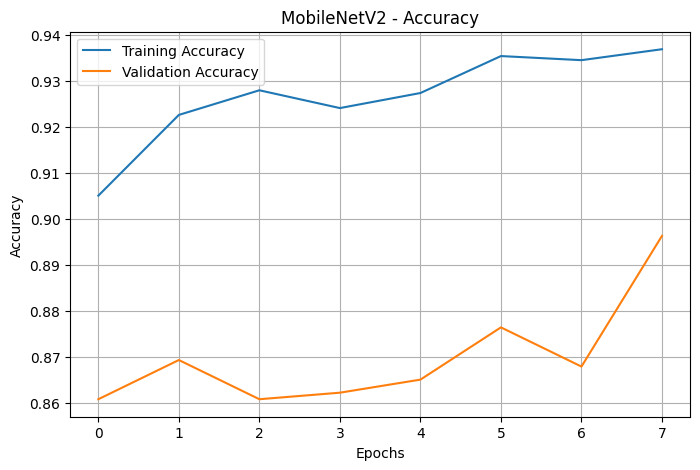

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

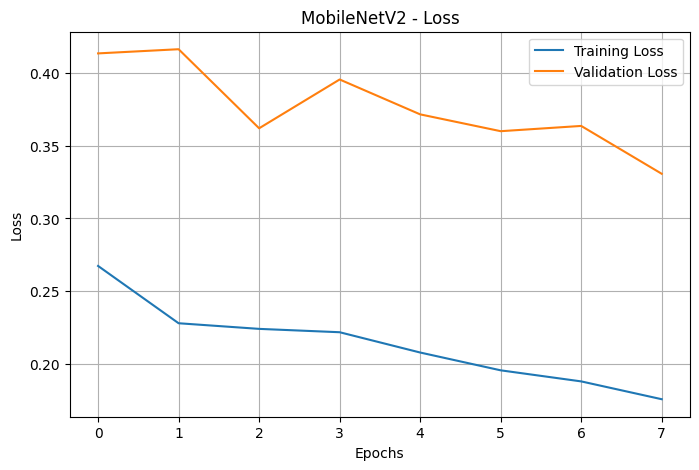

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("MobileNetV2 - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [55]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 208ms/step - accuracy: 0.8653 - loss: 0.4001
Test Loss: 0.4001171588897705
Test Accuracy: 86.53061389923096 %


In [60]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [61]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.79      0.95      0.86        80
                        Tomato_Early_blight       0.88      0.44      0.59        52
                         Tomato_Late_blight       0.94      0.85      0.89        85
                           Tomato_Leaf_Mold       0.88      0.86      0.87        50
                  Tomato_Septoria_leaf_spot       0.80      0.91      0.85        75
Tomato_Spider_mites_Two_spotted_spider_mite       0.94      0.79      0.86        78
                        Tomato__Target_Spot       0.69      0.86      0.76        76
      Tomato__Tomato_YellowLeaf__Curl_Virus       1.00      0.95      0.97       155
                Tomato__Tomato_mosaic_virus       1.00      0.93      0.97        15
                             Tomato_healthy       0.83      0.97      0.89        69

                                   accuracy                    

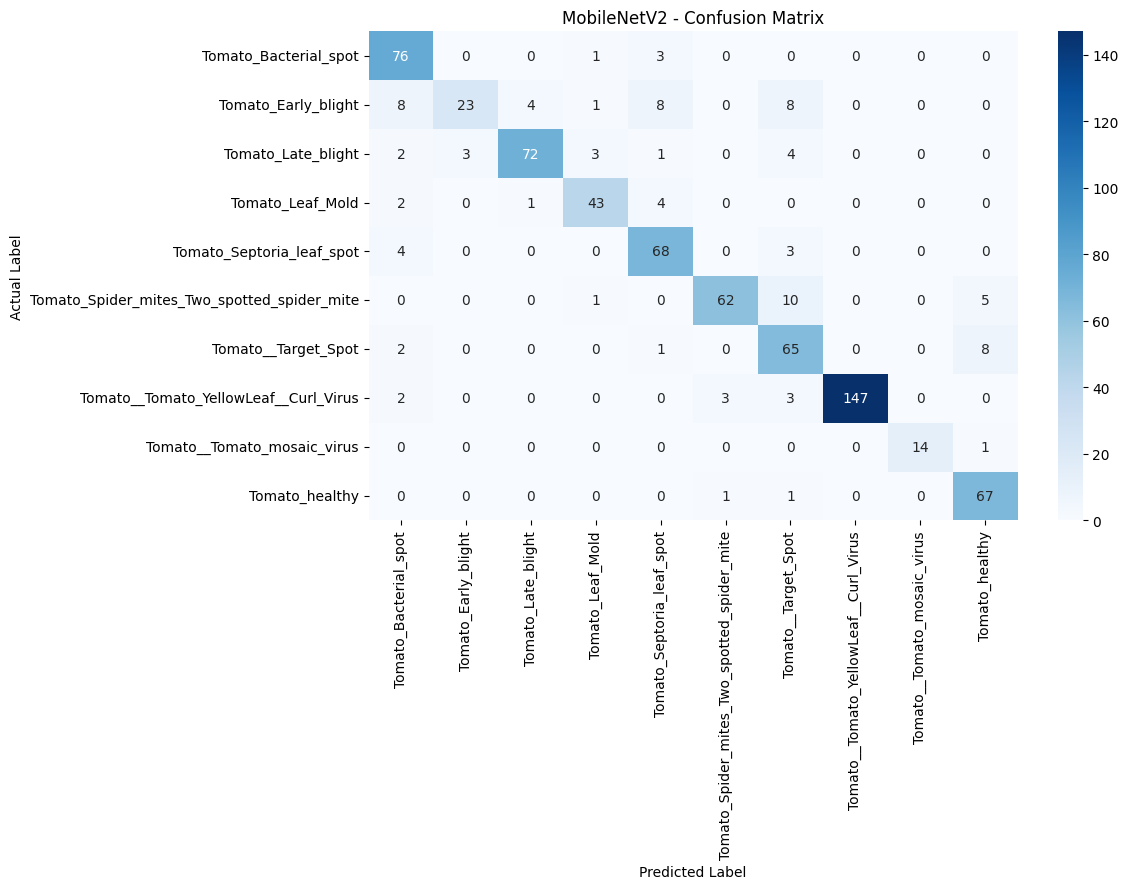

In [64]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [65]:
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    model_path / "mobilenetv2_classification_report.csv"
)

print("Classification report saved!")

Classification report saved!


In [67]:
evaluation_results = pd.DataFrame({
    "Model": ["MobileNetV2"],
    "Test Accuracy": [test_accuracy],
    "Test Loss": [test_loss]
})

evaluation_results.to_csv(
    model_path / "mobilenetv2_evaluation_results.csv",
    index=False
)

print(evaluation_results)

         Model  Test Accuracy  Test Loss
0  MobileNetV2       0.865306   0.400117


In [68]:
from pathlib import Path

model_path = Path("../models")
model_path.mkdir(parents=True, exist_ok=True)

model.save(model_path / "tomato_disease_mobilenetv2.keras")

print("mobilenetv2 Model saved successfully!")

mobilenetv2 Model saved successfully!


In [69]:
import os
file = "../models/tomato_disease_mobilenetv2.keras"

print(os.path.exists(file))

True


In [70]:
print("Saved files:")

for file in model_path.iterdir():
    print(file.name)

Saved files:
mobilenetv2_classification_report.csv
mobilenetv2_evaluation_results.csv
mobilenetv2_training_history.csv
tomato_disease_cnn.keras
tomato_disease_mobilenetv2.keras
